# 第100讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Experiment file present:', pathlib.Path('experiment.py').is_file())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Experiment file present: True


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "checks": {
    "reference_output_error": 2.220446049250313e-16,
    "reference_input_gradient_error": 2.220446049250313e-16,
    "reference_parameter_gradient_error": 1.3322676295501878e-15,
    "permutation_equivariance_error": 6.661338147750939e-16,
    "no_position_pool_change": 2.220446049250313e-16,
    "with_position_pool_change": 0.08991860936348395,
    "causal_future_error": 0.0,
    "parameters_measured": 600,
    "parameters_formula": 600
  },
  "order_task": [
    {
      "seed": 0,
      "position": false,
      "accuracy": 0.5,
      "loss": 0.6931472420692444
    },
    {
      "seed": 0,
      "position": true,
      "accuracy": 1.0,
      "loss": 0.0
    },
    {
      "seed": 1,
      "position": false,
      "accuracy": 0.5,
      "loss": 0.6931471824645996
    },
    {
      "seed": 1,
      "position": true,
      "accuracy": 1.0,
      "loss": 0.0
    },
    {
      "seed": 2,
      "position": false,
      "accuracy": 0.5,
      "loss": 0.6931471228599548
  

In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+'\n'.join(line for line in result.stderr.splitlines() if line.strip() != 'Fontconfig error: No writable cache directories'))

test_all_blocked (test_experiment.Tests.test_all_blocked) ... ok
test_causal_future (test_experiment.Tests.test_causal_future) ... ok
test_equivariance (test_experiment.Tests.test_equivariance) ... ok
test_forward_reference (test_experiment.Tests.test_forward_reference) ... ok
test_input_gradient (test_experiment.Tests.test_input_gradient) ... ok
test_parameter_gradients (test_experiment.Tests.test_parameter_gradients) ... ok
test_parameters (test_experiment.Tests.test_parameters) ... ok
test_pool_invariance (test_experiment.Tests.test_pool_invariance) ... ok
test_position_shape (test_experiment.Tests.test_position_shape) ... ok
test_positions_break_symmetry (test_experiment.Tests.test_positions_break_symmetry) ... ok

----------------------------------------------------------------------
Ran 10 tests in 0.011s

OK


In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['checks', 'order_task', 'configuration']


01_order.png
02_mechanism.png


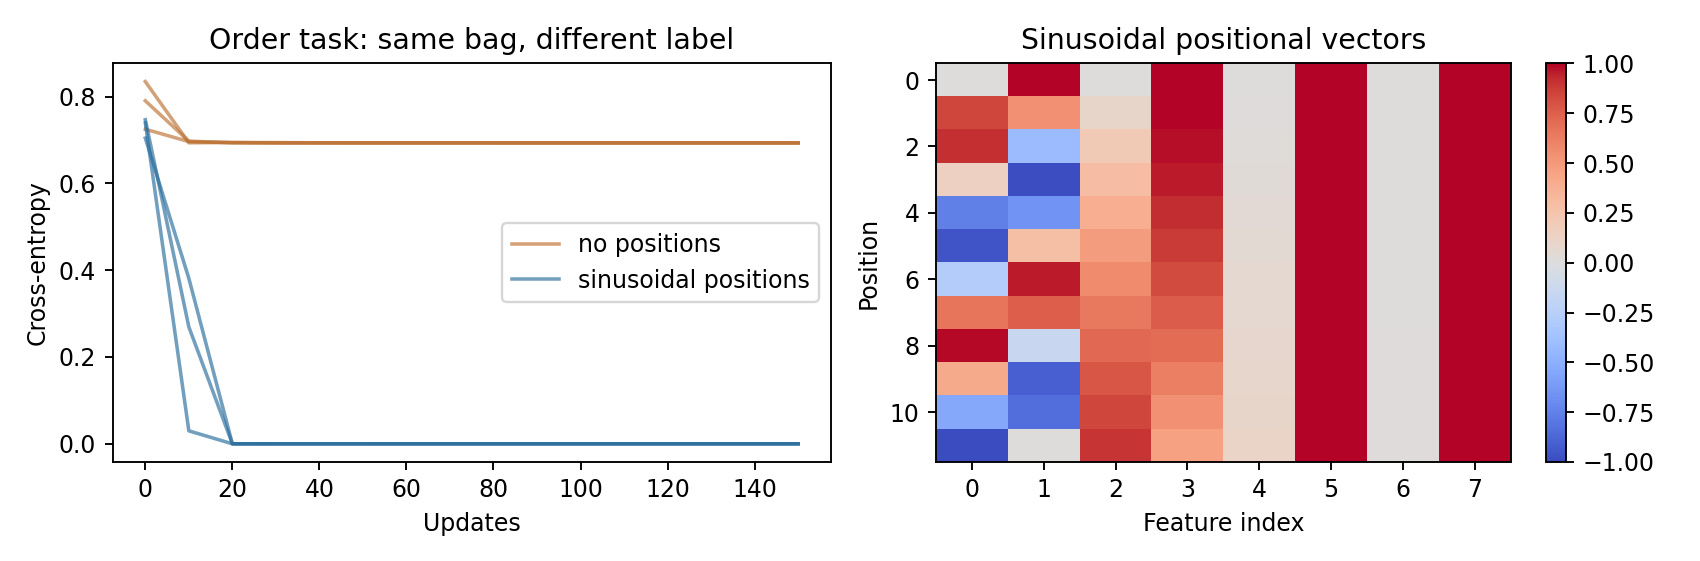

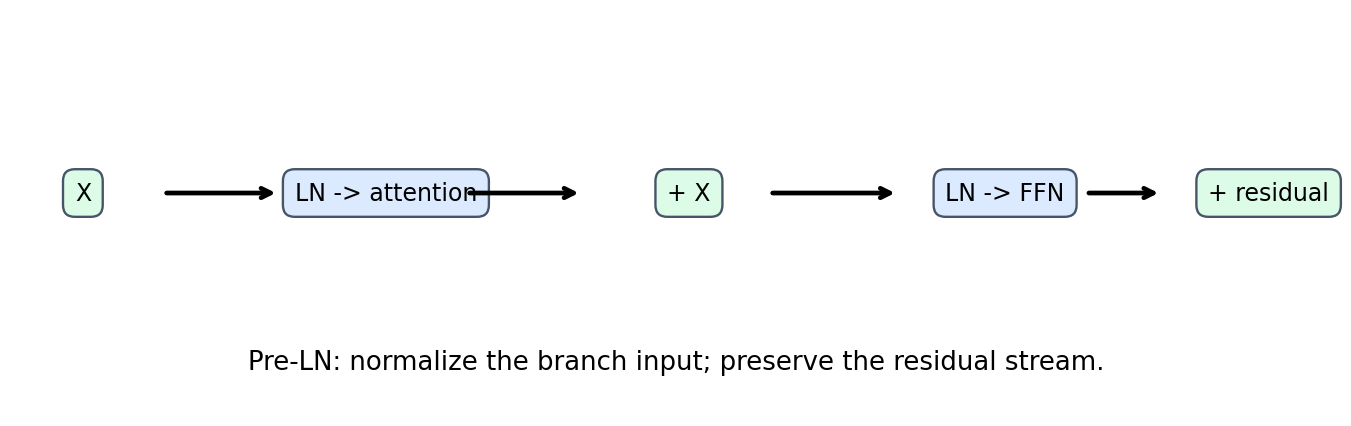

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。